# Análise de Inflação com Preços de Petróleo e Oferta Monetária (M2)

**Integrantes:**
*   Arthur Fetter
*   Helena Rocha
*   Fabio Junior

**Links dos Datasets Utilizados:**
*   **WTI Crude Oil Price (DCOILWTICO):** [https://fred.stlouisfed.org/series/DCOILWTICO](https://fred.stlouisfed.org/series/DCOILWTICO)
*   **Consumer Price Index (CPIAUCSL):** [https://fred.stlouisfed.org/series/CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL)
*   **M2 Money Stock (M2SL):** [https://fred.stlouisfed.org/series/M2SL](https://fred.stlouisfed.org/series/M2SL)

**Link da Apresentação:** [Link para a sua apresentação]

**Link do Vídeo:** [Link para o seu vídeo]

## 1. Importação e Preparação dos Dados

Nesta seção, importamos as bibliotecas necessárias e carregamos os três datasets públicos obtidos do Federal Reserve Economic Data (FRED):

- **DCOILWTICO:** Preço diário do petróleo bruto West Texas Intermediate (WTI), em USD por barril.
- **CPIAUCSL:** Índice de Preços ao Consumidor para todos os consumidores urbanos nos EUA, base 1982-84=100.
- **M2SL:** Estoque monetário M2 nos EUA, em bilhões de dólares, divulgado mensalmente.

### 1.1. Importação de Bibliotecas

In [749]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações para melhor visualização dos gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

### 1.2. Carregamento dos Datasets

Os três arquivos CSV foram baixados diretamente do FRED e salvos no mesmo diretório do notebook. Vamos carregar cada um em um DataFrame separado e inspecionar as primeiras linhas para entender sua
estrutura.

In [750]:
# Carregar Preço do Petróleo WTI
df_oil = pd.read_csv('DCOILWTICO.csv')
print("--- Preço do Petróleo WTI (DCOILWTICO) ---")
print(df_oil.head())
print("\n")

# Carregar Índice de Preços ao Consumidor (CPIAUCSL)
df_cpi = pd.read_csv('CPIAUCSL.csv')
print("--- Índice de Preços ao Consumidor (CPIAUCSL) ---")
print(df_cpi.head())
print("\n")

# Carregar M2 Money Stock (M2SL)
df_m2 = pd.read_csv('M2SL.csv')
print("--- M2 Money Stock (M2SL) ---")
print(df_m2.head())

--- Preço do Petróleo WTI (DCOILWTICO) ---
  observation_date  DCOILWTICO
0       1986-01-02       25.56
1       1986-01-03       26.00
2       1986-01-06       26.53
3       1986-01-07       25.85
4       1986-01-08       25.87


--- Índice de Preços ao Consumidor (CPIAUCSL) ---
  observation_date  CPIAUCSL
0       1947-01-01     21.48
1       1947-02-01     21.62
2       1947-03-01     22.00
3       1947-04-01     22.00
4       1947-05-01     21.95


--- M2 Money Stock (M2SL) ---
  observation_date   M2SL
0       1959-01-01  286.6
1       1959-02-01  287.7
2       1959-03-01  289.2
3       1959-04-01  290.1
4       1959-05-01  292.2


## 2. Análise Exploratória dos Dados

Nesta etapa, analisamos as dimensões, tipos de variáveis, presença de valores ausentes e estatísticas descritivas de cada dataset individualmente, antes de consolidá-los.

### 2.1. Informações dos DataFrames

Verificamos o tipo de cada coluna e a presença de valores nulos.

In [751]:
print("--- df_oil.info() ---")
df_oil.info()
print("\n")

print("--- df_cpi.info() ---")
df_cpi.info()
print("\n")

print("--- df_m2.info() ---")
df_m2.info()

--- df_oil.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 10664 entries, 0 to 10663
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  10664 non-null  str    
 1   DCOILWTICO        9547 non-null   float64
dtypes: float64(1), str(1)
memory usage: 166.8 KB


--- df_cpi.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  958 non-null    str    
 1   CPIAUCSL          957 non-null    float64
dtypes: float64(1), str(1)
memory usage: 15.1 KB


--- df_m2.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  813 non-null    str    
 1   M2SL              813 non-n

### 2.2. Estatísticas Descritivas

Usamos o método `.describe()` para obter alguns dados de cada série. Isso nos dá uma primeira visão da distribuição dos dados.

In [752]:
print("--- df_oil.describe() ---")
print(df_oil.describe())
print("\n")

print("--- df_cpi.describe() ---")
print(df_cpi.describe())
print("\n")

print("--- df_m2.describe() ---")
print(df_m2.describe())

--- df_oil.describe() ---
        DCOILWTICO
count  9547.000000
mean     50.154616
std      29.937007
min     -36.980000
25%      20.515000
50%      47.290000
75%      73.505000
max     145.310000


--- df_cpi.describe() ---
         CPIAUCSL
count  957.000000
mean   126.027460
std     91.247901
min     21.480000
25%     32.900000
50%    110.400000
75%    202.900000
max    337.476000


--- df_m2.describe() ---
               M2SL
count    813.000000
mean    5871.974170
std     6303.004469
min      286.600000
25%     1016.300000
50%     3410.900000
75%     8473.100000
max    23413.900000


## 3. Pré-processamento e Junção dos Dados

Nesta seção, realizamos as transformações necessárias para consolidar os três datasets em um único DataFrame mensal e alinhado temporalmente.

### 3.1. Conversão de Datas e Renomeação de Colunas

Os arquivos do FRED utilizam `observation_date` como nome da coluna de data. Convertemos essa coluna para o tipo `datetime` e a definimos como índice. Também renomeamos as colunas de valor para nomes mais
descritivos.

Adicionalmente, substituímos eventuais valores inválidos (representados como `.` nos arquivos do FRED) por `NaN`.

In [753]:
def preprocess_df(df, value_col_name):
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.set_index('observation_date')
    df.columns = [value_col_name]
    df = df.replace('.', pd.NA).astype(float)
    return df

df_oil = preprocess_df(df_oil, 'preco_petroleo')
df_cpi = preprocess_df(df_cpi, 'cpi')
df_m2 = preprocess_df(df_m2, 'm2')

print("DataFrames após conversão de datas e renomeação:")
print("df_oil.head():\n", df_oil.head())
print("\ndf_cpi.head():\n", df_cpi.head())
print("\ndf_m2.head():\n", df_m2.head())

DataFrames após conversão de datas e renomeação:
df_oil.head():
                   preco_petroleo
observation_date                
1986-01-02                 25.56
1986-01-03                 26.00
1986-01-06                 26.53
1986-01-07                 25.85
1986-01-08                 25.87

df_cpi.head():
                     cpi
observation_date       
1947-01-01        21.48
1947-02-01        21.62
1947-03-01        22.00
1947-04-01        22.00
1947-05-01        21.95

df_m2.head():
                      m2
observation_date       
1959-01-01        286.6
1959-02-01        287.7
1959-03-01        289.2
1959-04-01        290.1
1959-05-01        292.2


### 3.2. Reamostragem do Preço do Petróleo (Diário → Mensal)

O preço do petróleo é registrado diariamente, enquanto o CPI e o M2 são mensais. Para alinhar as séries temporais, reamostraremos o `df_oil` para frequência mensal calculando a **média mensal** do preço do petróleo.

In [754]:
df_oil_mensal = df_oil.resample('MS').mean()

print("df_oil após reamostragem mensal:\n", df_oil_mensal.head())
print("\nValores nulos em df_oil_mensal:\n", df_oil_mensal.isnull().sum())

df_oil após reamostragem mensal:
                   preco_petroleo
observation_date                
1986-01-01             23.114762
1986-02-01             15.381111
1986-03-01             12.568889
1986-04-01             12.836190
1986-05-01             15.418421

Valores nulos em df_oil_mensal:
 preco_petroleo    0
dtype: int64


### 3.3. Junção dos DataFrames

Unimos os três DataFrames em um único DataFrame consolidado usando o índice de data como chave. Utilizamos um `outer merge` para preservar todas as datas, e em seguida:
- Limitamos o período a partir de **Janeiro de 1986**, início da série histórica do WTI.
- Aplicamos `ffill` e `bfill` para preencher eventuais valores ausentes.
- Aplicamos interpolação temporal para gaps maiores.

In [755]:
df_merged = df_cpi.merge(df_m2, left_index=True, right_index=True, how='outer')
df_merged = df_merged.merge(df_oil_mensal, left_index=True, right_index=True, how='outer')

# Ordenar por data
df_merged = df_merged.sort_index()

df_merged = df_merged[df_merged.index >= '1986-01-01']

# Tratar valores nulos: ffill para preencher pra frente, bfill para preencher para trás
df_merged = df_merged.ffill().bfill()

# Interpolar valores restantes (se houver, para gaps maiores)
df_merged = df_merged.interpolate(method='time')

print("DataFrame merged após junção e tratamento de nulos:\n", df_merged.head())
print("\nValores nulos no df_merged:\n", df_merged.isnull().sum())

DataFrame merged após junção e tratamento de nulos:
                     cpi      m2  preco_petroleo
observation_date                               
1986-01-01        109.9  2501.6       23.114762
1986-02-01        109.7  2512.5       15.381111
1986-03-01        109.1  2533.1       12.568889
1986-04-01        108.7  2558.1       12.836190
1986-05-01        109.0  2585.7       15.418421

Valores nulos no df_merged:
 cpi               0
m2                0
preco_petroleo    0
dtype: int64


### 3.4. Cálculo da Inflação

A inflação é calculada como a **variação percentual do CPI** em relação ao mesmo mês do ano anterior (Year-over-Year ou YoY), que é a forma padrão utilizada por bancos centrais e institutos de estatística.

Calculamos também a inflação mensal (Month-over-Month ou MoM), que será utilizada como feature no modelo.

In [756]:
# Calcular inflação mensal (Month-over-Month - MoM)
df_merged['inflacao_mensal'] = df_merged['cpi'].pct_change() * 100

# Calcular inflação anual (Year-over-Year - YoY)
df_merged['inflacao_anual'] = df_merged['cpi'].pct_change(periods=12) * 100

# Remover os primeiros 12 valores nulos da inflação anual
df_merged = df_merged.dropna(subset=['inflacao_anual'])

print("DataFrame final com inflação mensal e anual:\n", df_merged.head(15))
print("\nInformações do DataFrame final:\n")
df_merged.info()

DataFrame final com inflação mensal e anual:
                     cpi      m2  preco_petroleo  inflacao_mensal  \
observation_date                                                   
1987-01-01        111.4  2743.3       18.654500         0.541516   
1987-02-01        111.8  2747.0       17.720556         0.359066   
1987-03-01        112.2  2753.5       18.410526         0.357782   
1987-04-01        112.7  2767.8       18.669500         0.445633   
1987-05-01        113.0  2773.7       19.431053         0.266193   
1987-06-01        113.5  2775.3       20.098500         0.442478   
1987-07-01        113.8  2779.0       21.369000         0.264317   
1987-08-01        114.3  2788.3       20.310952         0.439367   
1987-09-01        114.7  2799.6       19.530000         0.349956   
1987-10-01        115.0  2814.7       19.854286         0.261552   
1987-11-01        115.4  2818.9       18.854000         0.347826   
1987-12-01        115.6  2826.7       17.095000         0.173310   
19

 ### 3.5. Engenharia de Features — Variações Percentuais

Como vimos na matriz de correlação inicial, o nível absoluto do preço do petróleo e do M2 têm baixa correlação com a inflação. Isso faz sentido, pois a inflação é uma variação, não um nível.

Por isso, calculamos as variações percentuais anuais do petróleo e do M2, que capturam melhor a dinâmica inflacionária.

In [757]:
df_merged['variacao_petroleo_mensal'] = df_merged['preco_petroleo'].pct_change() * 100

# Variação percentual anual do preço do petróleo (Year-over-Year)
df_merged['variacao_petroleo_anual'] = df_merged['preco_petroleo'].pct_change(periods=12) * 100

# Variação percentual anual do M2 (Year-over-Year)
df_merged['variacao_m2_anual'] = df_merged['m2'].pct_change(periods=12) * 100

# Remover linhas com NaN gerados pelas variações (primeiros 12 meses)
df_merged = df_merged.dropna()

print("Novas features adicionadas:")
print(df_merged[['preco_petroleo', 'variacao_petroleo_anual',
'variacao_m2_anual', 'inflacao_anual']].head(10))
print(f"\nTotal de registros após remoção de NaN: {len(df_merged)}")

Novas features adicionadas:
                  preco_petroleo  variacao_petroleo_anual  variacao_m2_anual  \
observation_date                                                               
1988-01-01             17.129500                -8.174971           3.776474   
1988-02-01             16.795714                -5.219031           4.463051   
1988-03-01             16.235909               -11.811815           4.964591   
1988-04-01             17.862500                -4.322558           5.152106   
1988-05-01             17.423636               -10.330970           5.512492   
1988-06-01             16.566000               -17.575939           5.898461   
1988-07-01             15.497500               -27.476719           6.052537   
1988-08-01             15.523478               -23.570899           5.874547   
1988-09-01             14.535455               -25.573709           5.629376   
1988-10-01             13.770476               -30.642299           5.354034   

           

### 3.6. Análise de Defasagem (Lag Analysis) M2

A teoria econômica sugere que os efeitos da expansão monetária sobre a inflação não são imediatos, eles se manifestam com uma defasagem de meses ou até anos.

Medimos a correlação entre a variação do M2 e a inflação anual com defasagens de 1 a 24 meses, para identificar o período de maior impacto. O resultado indica que o M2 tem maior poder preditivo com aproximadamente 17 a 19 meses de defasagem.

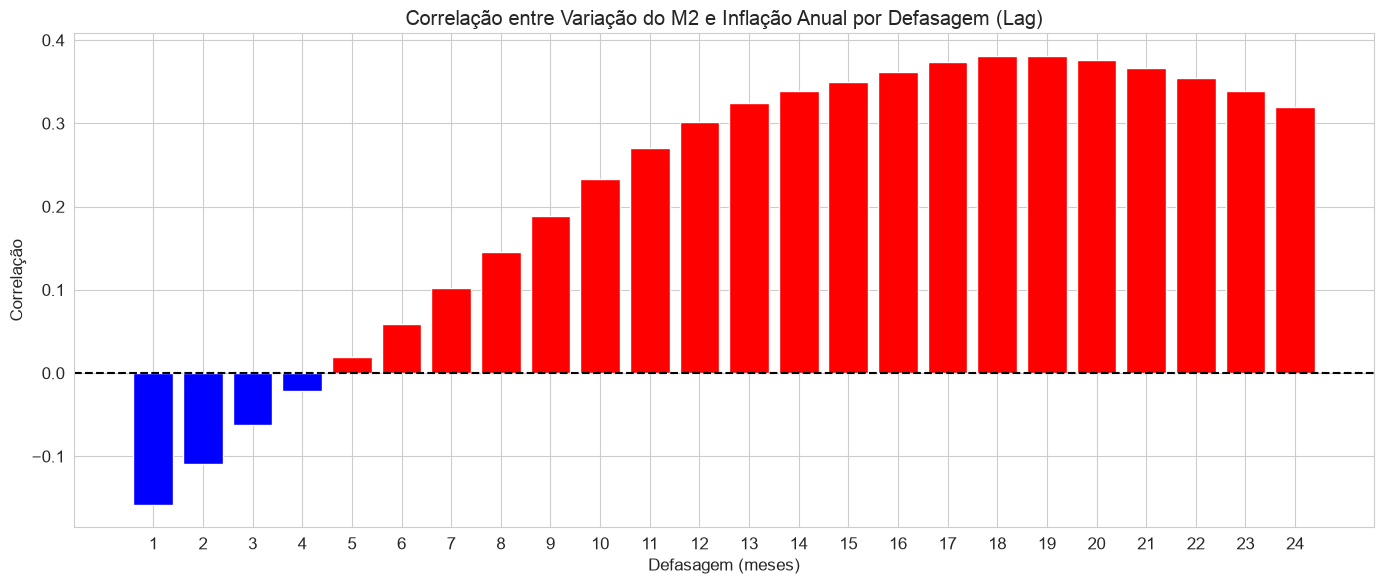

 Lag (meses)  Correlação
           1   -0.158433
           2   -0.109452
           3   -0.062872
           4   -0.021289
           5    0.019258
           6    0.059537
           7    0.102009
           8    0.145285
           9    0.189180
          10    0.232828
          11    0.271041
          12    0.301239
          13    0.324059
          14    0.338444
          15    0.349710
          16    0.361856
          17    0.373222
          18    0.380653
          19    0.381240
          20    0.376070
          21    0.366631
          22    0.354088
          23    0.338771
          24    0.319366

Maior correlação: Lag = 19 meses (correlação = 0.38)


In [758]:
lags = range(1, 25)  # Testar defasagens de 1 a 24 meses
correlacoes = []

for lag in lags:
    # Deslocar a variacao_m2_anual 'lag' meses para frente
    corr = df_merged['variacao_m2_anual'].shift(lag).corr(df_merged['inflacao_anual'])
    correlacoes.append(corr)

# Plotar as correlações por defasagem
plt.figure(figsize=(14, 6))
plt.bar(lags, correlacoes, color=['red' if c > 0 else 'blue' for c in correlacoes])
plt.axhline(0, color='black', linestyle='--')
plt.title('Correlação entre Variação do M2 e Inflação Anual por Defasagem (Lag)')
plt.xlabel('Defasagem (meses)')
plt.ylabel('Correlação')
plt.xticks(list(lags))
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

# Exibir a tabela de correlações
import pandas as pd
df_lags = pd.DataFrame({'Lag (meses)': list(lags), 'Correlação': correlacoes})
print(df_lags.to_string(index=False))
print(f"\nMaior correlação: Lag = {df_lags.loc[df_lags['Correlação'].idxmax(), 'Lag (meses)']} meses "
      f"(correlação = {df_lags['Correlação'].max():.2f})")

df_merged['variacao_m2_lag18'] = df_merged['variacao_m2_anual'].shift(18)
df_merged = df_merged.dropna()

### 3.7. Análise de Correlação Cruzada: Acumulados do M2 vs Inflação Futura

Exploramos sistematicamente a correlação entre diferentes janelas de acumulação do M2 (3 a 24 meses) e diferentes janelas de inflação futura acumulada (3 a 24 meses).

O resultado mostra que a combinação M2 acumulado de 6-12 meses com inflação futura acumulada de 15-18 meses apresenta as maiores correlações (~0.45).

In [759]:
df_merged['inflacao_acumulada_18m'] = (
    df_merged['inflacao_mensal']
    .rolling(window=18)
    .sum()
    .shift(-18)
)

df_merged['inflacao_acumulada_12m'] = (
    df_merged['inflacao_mensal']
    .rolling(window=12)
    .sum()
    .shift(-12)
)

df_merged['cpi_acumulado_18m'] = (
    df_merged['cpi'].shift(-18) - df_merged['cpi']
) / df_merged['cpi'] * 100

In [760]:
df_merged['m2_acum_9m'] = df_merged['variacao_m2_anual'].rolling(window=9).mean()

df_merged['m2_acum_6m'] = df_merged['variacao_m2_anual'].rolling(window=6).mean()

df_merged['m2_acum_12m'] = df_merged['variacao_m2_anual'].rolling(window=12).mean()

df_merged['inflacao_acumulada_18m'] = (
    df_merged['inflacao_mensal']
    .rolling(window=18)
    .sum()
    .shift(-18)
)

df_merged = df_merged.dropna()

print("Features adicionadas:")
print(df_merged[['variacao_m2_anual', 'm2_acum_6m', 'm2_acum_9m', 'm2_acum_12m',
'inflacao_acumulada_18m']].head(10))
print(f"\nTotal de registros: {len(df_merged)}")
print(f"Período: {df_merged.index.min()} até {df_merged.index.max()}")

Features adicionadas:
                  variacao_m2_anual  m2_acum_6m  m2_acum_9m  m2_acum_12m  \
observation_date                                                           
1990-06-01                 6.141451    6.230891    5.895289     5.447406   
1990-07-01                 5.641278    6.195465    5.964181     5.619772   
1990-08-01                 5.447863    6.061497    5.997969     5.727962   
1990-09-01                 5.231336    5.875776    5.967314     5.781506   
1990-10-01                 4.652731    5.565999    5.833858     5.750797   
1990-11-01                 4.123053    5.206285    5.597345     5.665736   
1990-12-01                 3.776876    4.812190    5.311924     5.521540   
1991-01-01                 3.824653    4.509419    5.013397     5.352442   
1991-02-01                 3.945630    4.259047    4.753875     5.160272   
1991-03-01                 4.132698    4.075940    4.530680     4.975858   

                  inflacao_acumulada_18m  
observation_date      

### 3.8. Features Finais

Com base na análise de correlação cruzada, adicionamos as features de acumulados do M2 (6, 9 e 12 meses) e definimos a **variável-alvo** como a inflação acumulada nos próximos 12 meses (`inflacao_acumulada_12m`).

A escolha de 12 meses como horizonte de previsão é justificada por:
1. Ser o horizonte padrão de política monetária dos bancos centrais.
2. Apresentar correlação consistente com as features do M2.
3. Ser facilmente interpretável como "inflação do próximo ano".

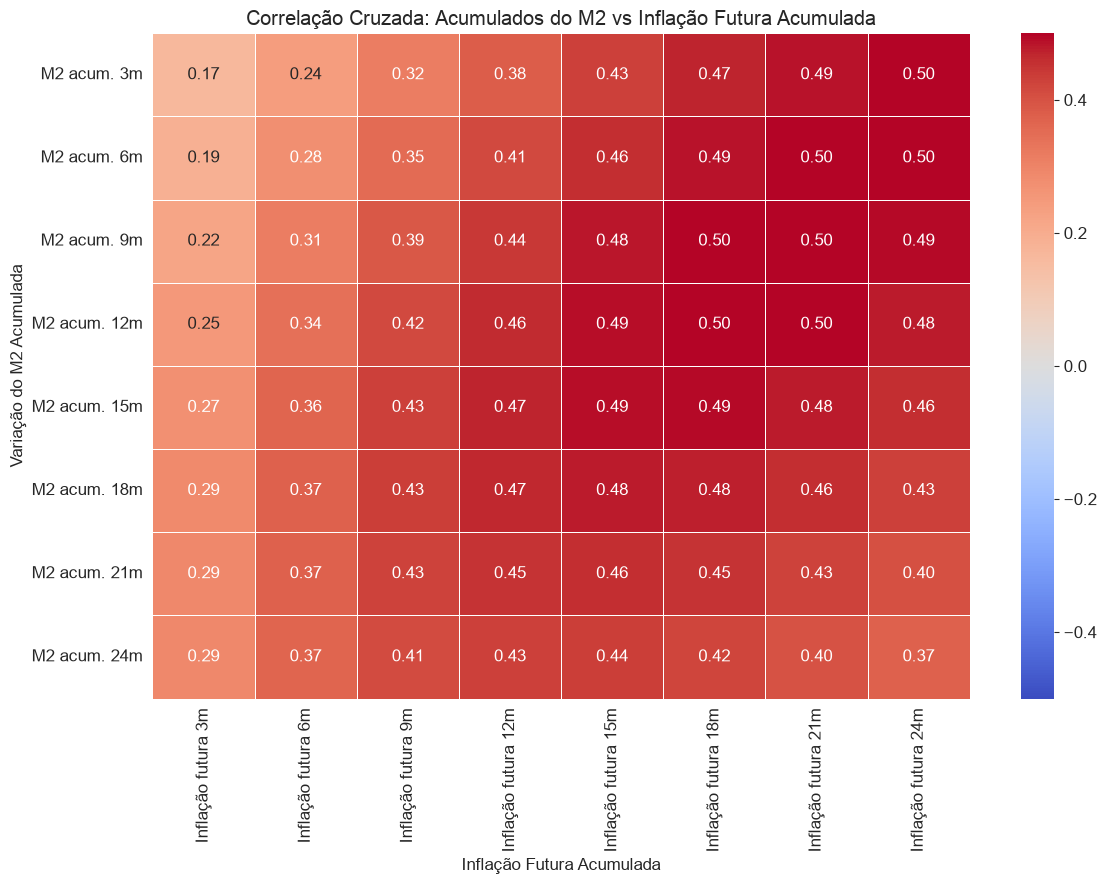


Maior correlação encontrada: 0.503
  M2 acumulado: 9 meses
  Inflação futura acumulada: 21 meses


In [761]:
import numpy as np

janelas = [3, 6, 9, 12, 15, 18, 21, 24]

# Matriz para armazenar as correlações
matriz_corr = np.zeros((len(janelas), len(janelas)))

for i, janela_m2 in enumerate(janelas):
    for j, janela_inflacao in enumerate(janelas):
        acumulado_m2 = df_merged['variacao_m2_anual'].rolling(window=janela_m2).mean()

        inflacao_futura = df_merged['inflacao_mensal'].rolling(window=janela_inflacao).sum().shift(-janela_inflacao)

        matriz_corr[i, j] = acumulado_m2.corr(inflacao_futura)

df_corr_cruzada = pd.DataFrame(
    matriz_corr,
    index=[f'M2 acum. {j}m' for j in janelas],
    columns=[f'Inflação futura {j}m' for j in janelas]
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    df_corr_cruzada,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-0.5,
    vmax=0.5
)
plt.title('Correlação Cruzada: Acumulados do M2 vs Inflação Futura Acumulada')
plt.xlabel('Inflação Futura Acumulada')
plt.ylabel('Variação do M2 Acumulada')
plt.tight_layout()
plt.show()

# Identificar a combinação com maior correlação
max_idx = np.unravel_index(np.argmax(matriz_corr), matriz_corr.shape)
print(f"\nMaior correlação encontrada: {matriz_corr[max_idx]:.3f}")
print(f"  M2 acumulado: {janelas[max_idx[0]]} meses")
print(f"  Inflação futura acumulada: {janelas[max_idx[1]]} meses")

## 4. Visualização dos Dados

Nesta seção, visualizamos as séries temporais dos principais indicadores e analisamos suas correlações.

### 4.1. Séries Temporais

Os gráficos abaixo mostram a evolução histórica de cada variável desde 1986. Destacam-se eventos como:
- **1990:** Guerra do Golfo — choque no preço do petróleo
- **2008:** Crise financeira global — queda abrupta do petróleo e deflação
- **2020-2022:** Pandemia COVID-19 — expansão massiva do M2 seguida de inflação histórica

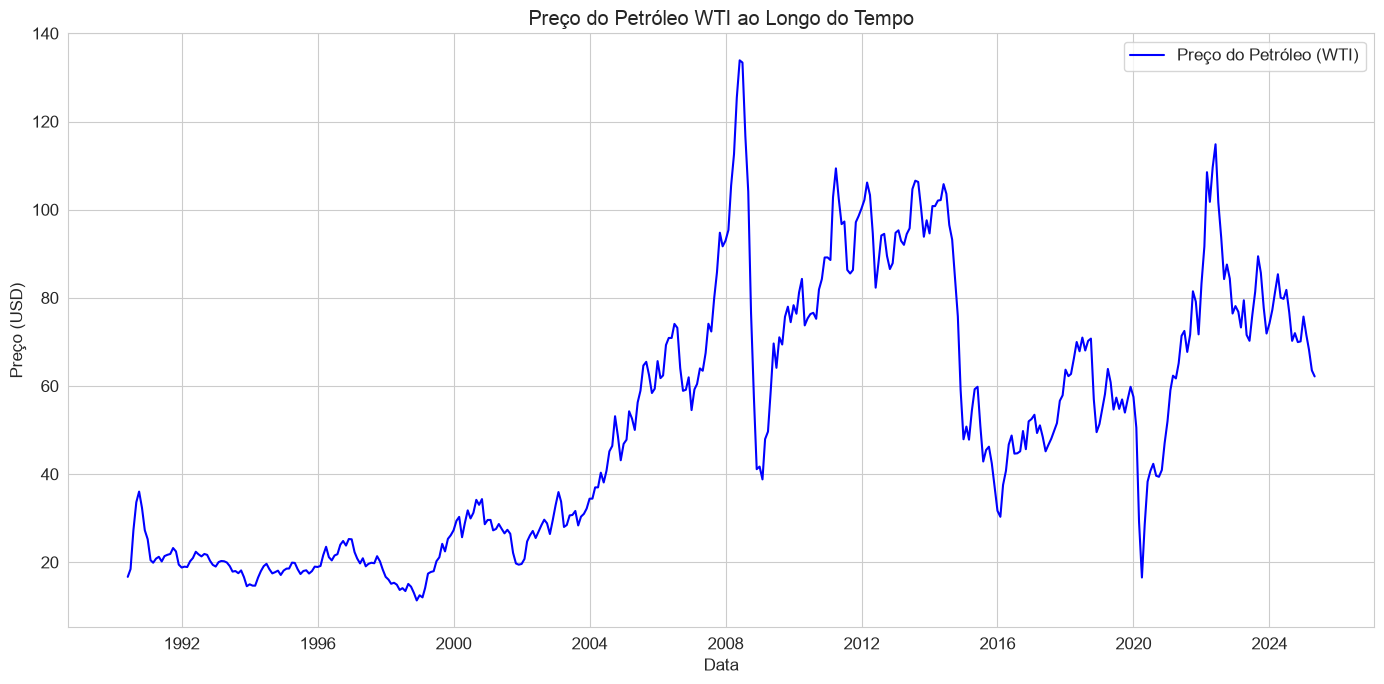

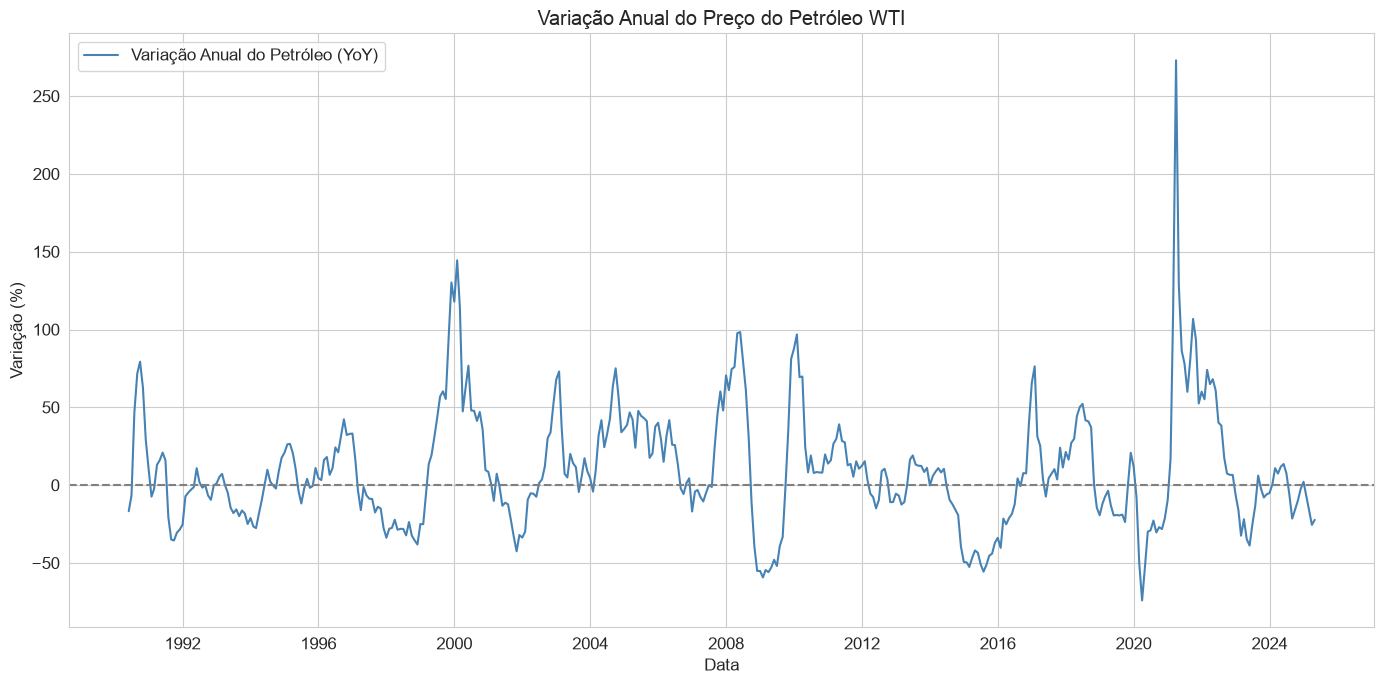

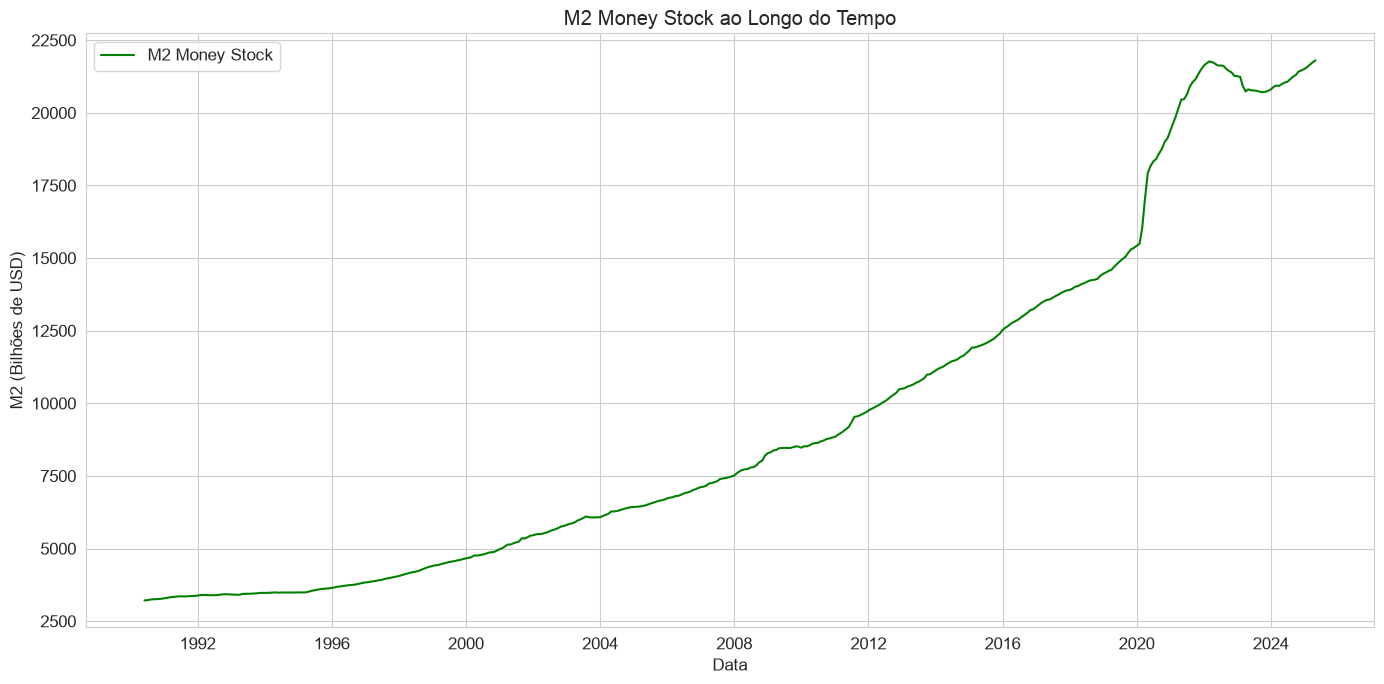

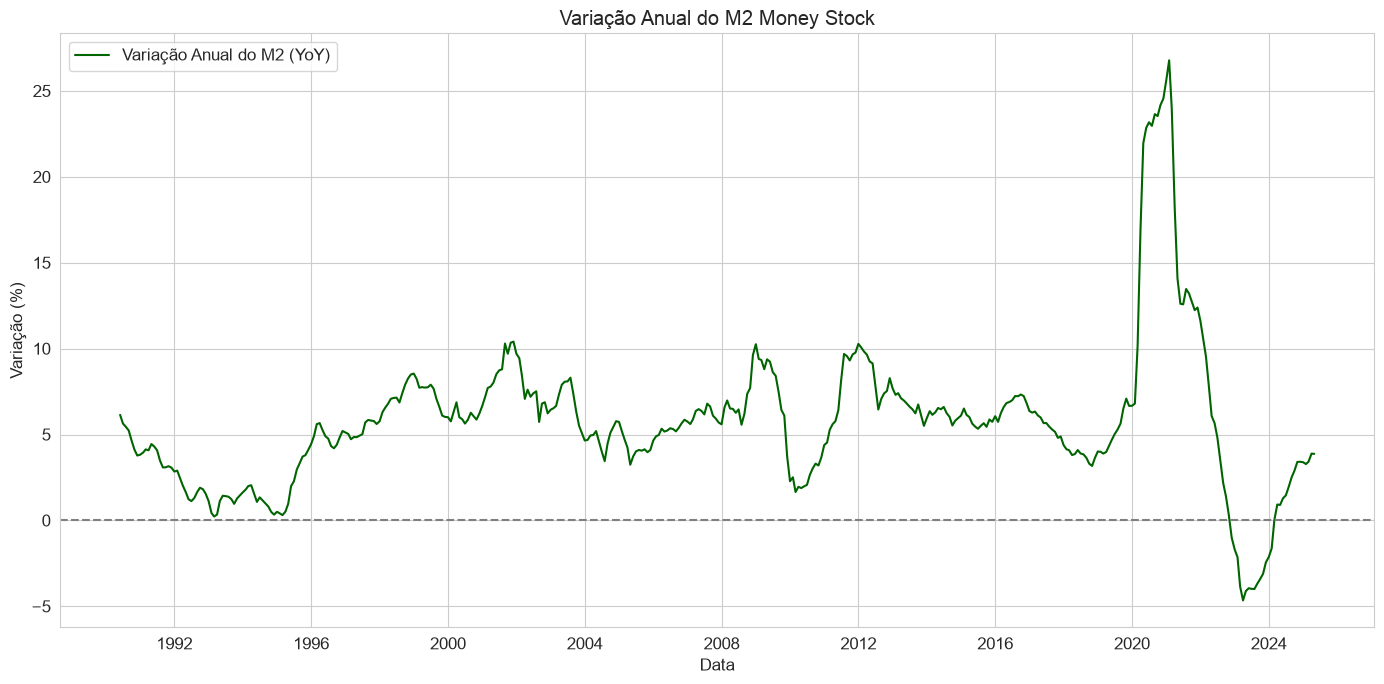

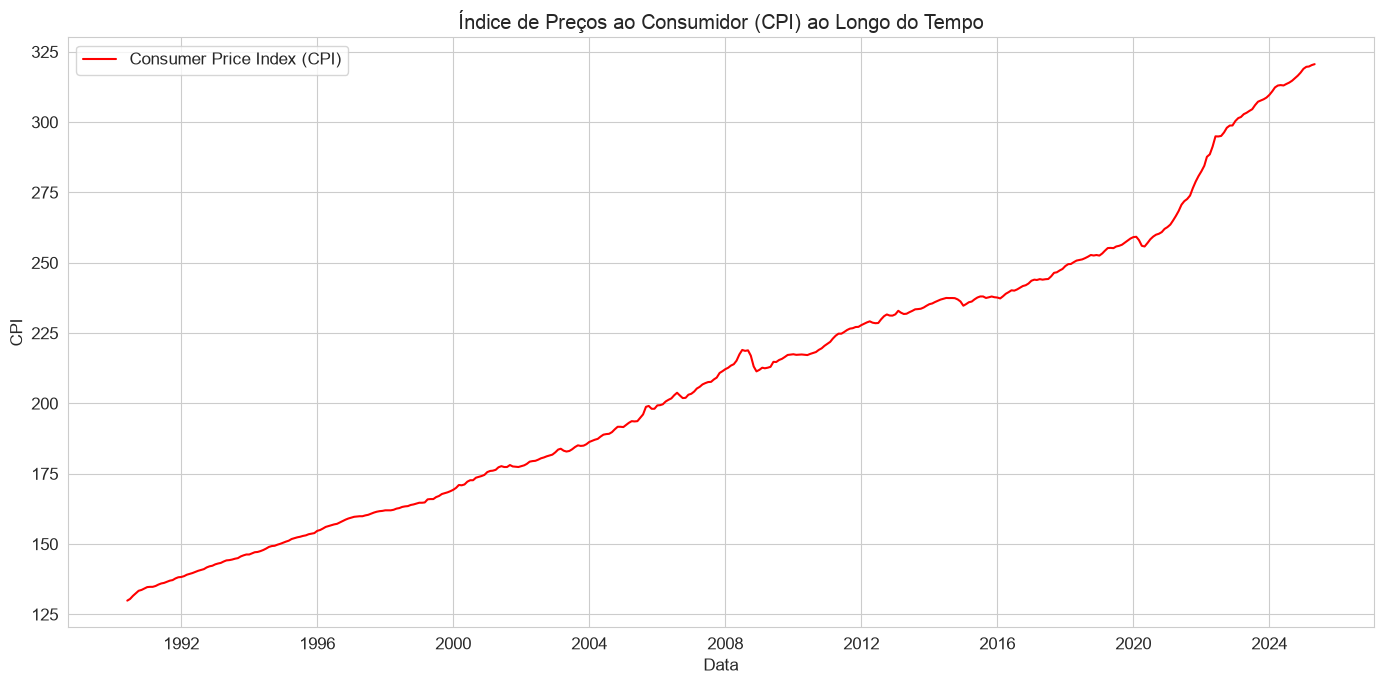

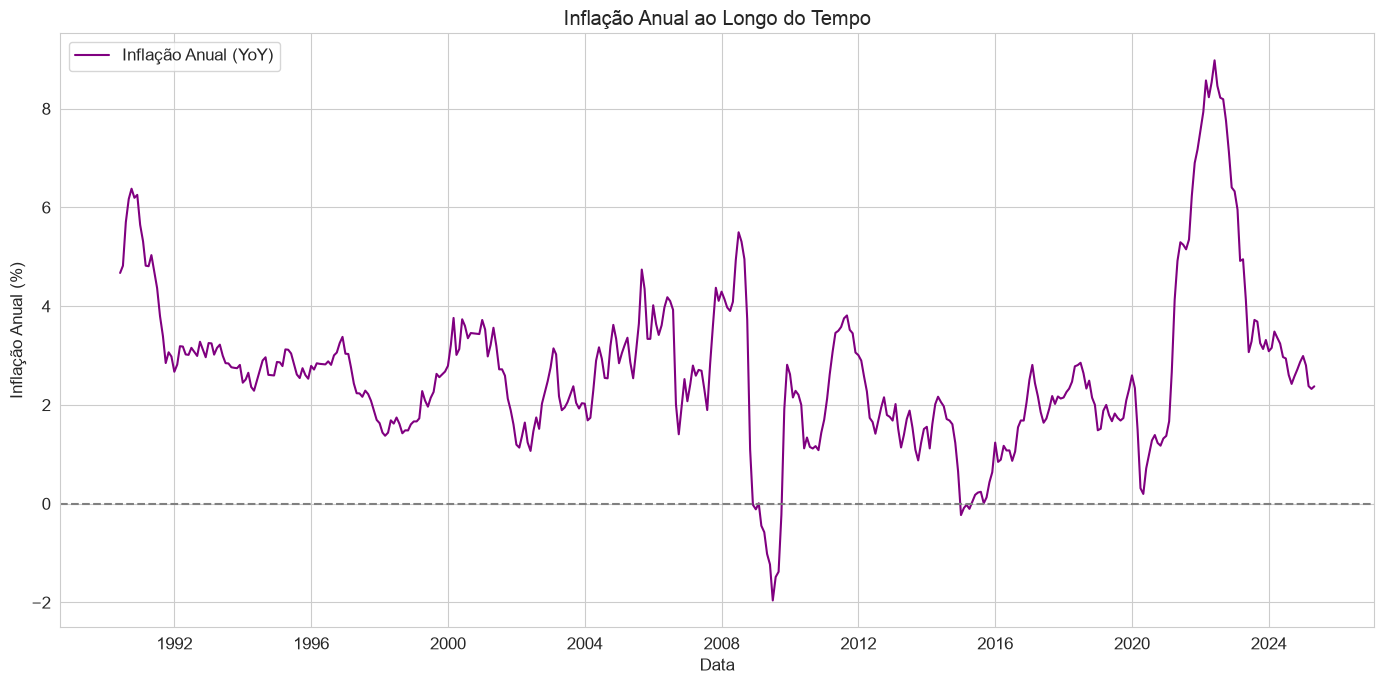

In [762]:
# Gráfico de Preço do Petróleo ao longo do tempo
plt.figure(figsize=(14, 7))
plt.plot(df_merged.index, df_merged['preco_petroleo'], label='Preço do Petróleo (WTI)', color='blue')
plt.title('Preço do Petróleo WTI ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Preço (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
plt.plot(df_merged.index, df_merged['variacao_petroleo_anual'],
label='Variação Anual do Petróleo (YoY)', color='steelblue')
plt.title('Variação Anual do Preço do Petróleo WTI')
plt.xlabel('Data')
plt.ylabel('Variação (%)')
plt.axhline(0, color='gray', linestyle='--')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Gráfico de M2 Money Stock ao longo do tempo
plt.figure(figsize=(14, 7))
plt.plot(df_merged.index, df_merged['m2'], label='M2 Money Stock', color='green')
plt.title('M2 Money Stock ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('M2 (Bilhões de USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Gráfico da Variação Anual do M2
plt.figure(figsize=(14, 7))
plt.plot(df_merged.index, df_merged['variacao_m2_anual'],
label='Variação Anual do M2 (YoY)', color='darkgreen')
plt.title('Variação Anual do M2 Money Stock')
plt.xlabel('Data')
plt.ylabel('Variação (%)')
plt.axhline(0, color='gray', linestyle='--')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Gráfico de CPI ao longo do tempo
plt.figure(figsize=(14, 7))
plt.plot(df_merged.index, df_merged['cpi'], label='Consumer Price Index (CPI)', color='red')
plt.title('Índice de Preços ao Consumidor (CPI) ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Gráfico de Inflação Anual ao longo do tempo
plt.figure(figsize=(14, 7))
plt.plot(df_merged.index, df_merged['inflacao_anual'], label='Inflação Anual (YoY)', color='purple')
plt.title('Inflação Anual ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Inflação Anual (%)')
plt.axhline(0, color='gray', linestyle='--')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 4.2. Matriz de Correlação

A matriz de correlação abaixo resume as relações entre todas as variáveis do dataset. Os principais achados são:

- **`m2_acum_9m`** é o melhor preditor da inflação acumulada de 12 meses (0.45)
- **`variacao_petroleo_anual`** captura choques de oferta de curto prazo (0.24)
- O **nível absoluto** do M2 e do petróleo têm correlação espúria com o CPI (tendência de longo prazo)

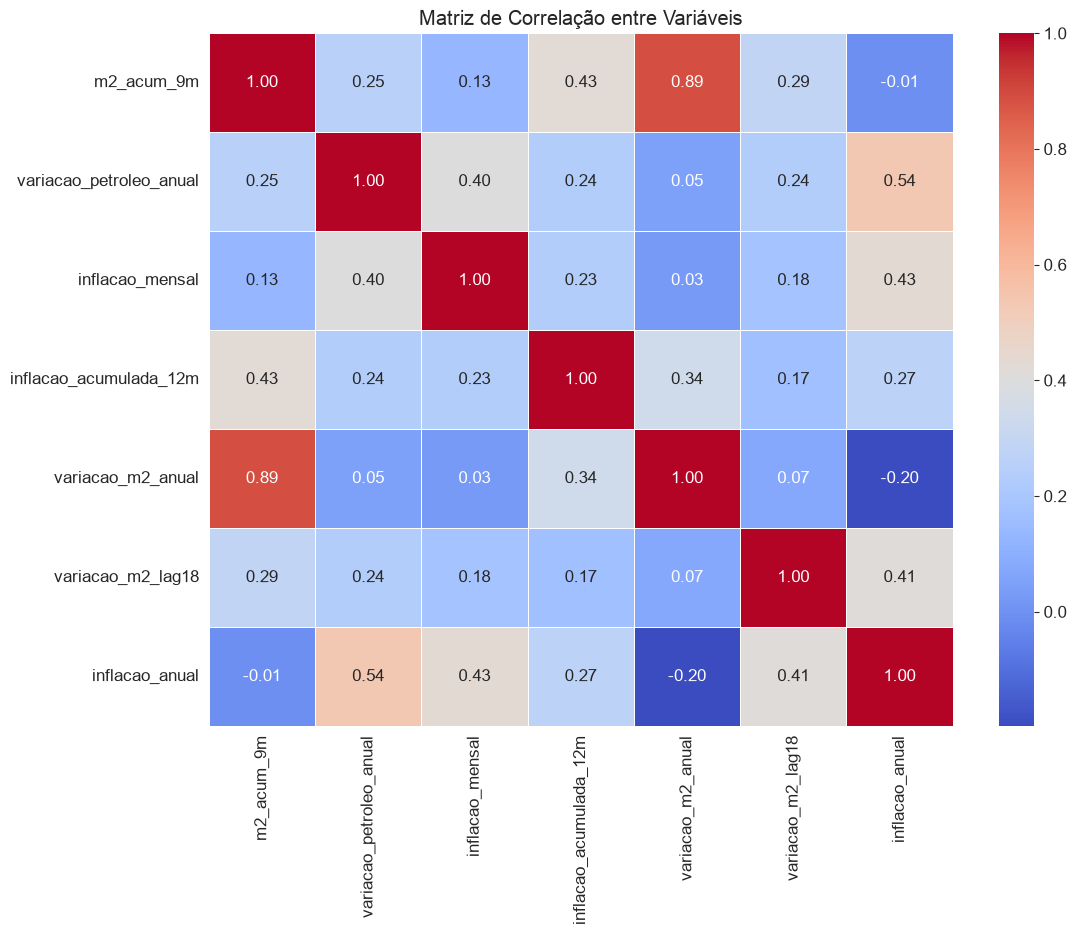

In [763]:
correlation_matrix = df_merged[[
    'm2_acum_9m',
    'variacao_petroleo_anual',
    'inflacao_mensal',

    'inflacao_acumulada_12m',

    'variacao_m2_anual',
    'variacao_m2_lag18',
    'inflacao_anual',
]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlação entre Variáveis')
plt.show()

## 5. Preparação para Modelagem

Nesta seção, realizaremos todas as etapas necessárias para preparar os dados para o treinamento do modelo de Machine Learning.

### 5.1. Classificação das Variáveis

Antes de iniciar a modelagem, é importante classificar as variáveis do nosso dataset:

| Variável | Tipo | Classificação |
|---|---|---|
| `m2_acum_9m` | Numérica | Contínua |
| `variacao_petroleo_anual` | Numérica | Contínua |
| `inflacao_mensal` | Numérica | Contínua |
| `inflacao_acumulada_12m` | Numérica | Contínua (variável-alvo) |

Todas as variáveis são **numéricas contínuas**, o que é esperado para dados econômicos de séries temporais.

### 5.2. Seleção de Features e Separação X/y

In [764]:
# Definir variável-alvo: inflação acumulada nos próximos 12 meses
df_merged['inflacao_acumulada_12m'] = (
    df_merged['inflacao_mensal']
    .rolling(window=12)
    .sum()
    .shift(-12)
)

# Remover linhas com NaN gerados pelo shift
df_merged = df_merged.dropna()

# Selecionar features (X) e variável-alvo (y)
features = ['m2_acum_9m', 'variacao_petroleo_anual', 'inflacao_mensal']
target = 'inflacao_acumulada_12m'
X = df_merged[features]
y = df_merged[target]

print("Features (X):")
print(X.head())
print(f"\nVariável-alvo (y):")
print(y.head())
print(f"\nDimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")

Features (X):
                  m2_acum_9m  variacao_petroleo_anual  inflacao_mensal
observation_date                                                      
1990-06-01          5.895289               -16.733867         0.619675
1990-07-01          5.964181                -6.710019         0.461894
1990-08-01          5.997969                46.971966         0.842912
1990-09-01          5.967314                71.780763         0.683891
1990-10-01          5.833858                79.321596         0.679245

Variável-alvo (y):
observation_date
1990-06-01    4.601251
1990-07-01    4.286416
1990-08-01    3.737190
1990-09-01    3.346125
1990-10-01    2.812866
Name: inflacao_acumulada_12m, dtype: float64

Dimensões de X: (408, 3)
Dimensões de y: (408,)


### 5.3. Divisão Temporal Treino/Teste

Como estamos trabalhando com séries temporais, não podemos usar o `train_test_split` aleatório do scikit-learn. Uma divisão aleatória causaria data leakage, pois o modelo poderia "ver" dados futuros durante o treinamento.

A solução correta é uma divisão temporal, onde os dados mais antigos são usados para treino e os mais recentes para teste. Vamos usar 80% dos dados para treino e 20% para teste.

In [765]:
# Divisão temporal: 80% treino, 20% teste
split_idx = int(len(X) * 0.8)
split_date = X.index[split_idx]

X_train = X.iloc[:split_idx]
X_test  = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test  = y.iloc[split_idx:]

print(f"Data de corte treino/teste: {split_date.strftime('%Y-%m')}")
print(f"\nTreino: {X_train.index.min().strftime('%Y-%m')} até {X_train.index.max().strftime('%Y-%m')} ({len(X_train)} registros)")
print(f"Teste:  {X_test.index.min().strftime('%Y-%m')} até {X_test.index.max().strftime('%Y-%m')} ({len(X_test)} registros)")

Data de corte treino/teste: 2017-08

Treino: 1990-06 até 2017-07 (326 registros)
Teste:  2017-08 até 2024-05 (82 registros)


### 5.4. Padronização dos Dados

Vamos padronizar as features usando o `StandardScaler`, que transforma cada feature para ter média 0 e desvio padrão 1. Isso é importante para modelos que são sensíveis à escala dos dados, como a Regressão Linear.

In [766]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit apenas no treino, transform em ambos
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Converter de volta para DataFrame para manter os nomes das colunas
X_train_scaled = pd.DataFrame(X_train_scaled, columns=features, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=features, index=X_test.index)

print("Features após padronização (treino):")
print(X_train_scaled.describe().round(2))

Features após padronização (treino):
       m2_acum_9m  variacao_petroleo_anual  inflacao_mensal
count      326.00                   326.00           326.00
mean        -0.00                     0.00             0.00
std          1.00                     1.00             1.00
min         -2.23                    -1.97            -7.52
25%         -0.47                    -0.60            -0.49
50%          0.23                    -0.10             0.02
75%          0.64                     0.52             0.46
max          1.93                     3.92             4.51


## 6. Modelagem

Nesta seção, treinaremos dois modelos de Machine Learning para prever a inflação acumulada nos próximos 12 meses:

1. **Regressão Linear**: modelo baseline, simples e interpretável
2. **Random Forest Regressor**: modelo mais sofisticado, capaz de capturar relações não-lineares

### 6.1. Modelo Baseline: Regressão Linear

In [767]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Treinar o modelo
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Predições
y_pred_lr = lr.predict(X_test_scaled)

# Métricas
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr   = r2_score(y_test, y_pred_lr)

print("=== Regressão Linear ===")
print(f"MAE:  {mae_lr:.3f}%")
print(f"RMSE: {rmse_lr:.3f}%")
print(f"R²:   {r2_lr:.3f}")

print("\nCoeficientes:")
for feature, coef in zip(features, lr.coef_):
    print(f"  {feature:<30} {coef:.4f}")
print(f"  {'Intercepto':<30} {lr.intercept_:.4f}")

=== Regressão Linear ===
MAE:  2.361%
RMSE: 3.481%
R²:   -1.457

Coeficientes:
  m2_acum_9m                     -0.3159
  variacao_petroleo_anual        0.0568
  inflacao_mensal                0.0358
  Intercepto                     2.2994


### 6.2. Modelo Principal: Random Forest Regressor

O Random Forest é um modelo de ensemble que combina múltiplas árvores de decisão, sendo capaz de capturar relações não-lineares entre as features e a variável-alvo.

In [768]:
from sklearn.ensemble import RandomForestRegressor

# Treinar o modelo
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42
)
rf.fit(X_train_scaled, y_train)

# Predições
y_pred_rf = rf.predict(X_test_scaled)

# Métricas
mae_rf  = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf   = r2_score(y_test, y_pred_rf)

print("=== Random Forest Regressor ===")
print(f"MAE:  {mae_rf:.3f}%")
print(f"RMSE: {rmse_rf:.3f}%")
print(f"R²:   {r2_rf:.3f}")

=== Random Forest Regressor ===
MAE:  1.980%
RMSE: 2.752%
R²:   -0.536


### 6.3. Comparação dos Modelos

In [769]:
# Tabela comparativa
print("=" * 45)
print(f"{'Modelo':<25} {'MAE':>6} {'RMSE':>7} {'R²':>7}")
print("=" * 45)
print(f"{'Regressão Linear':<25} {mae_lr:>6.3f} {rmse_lr:>7.3f} {r2_lr:>7.3f}")
print(f"{'Random Forest':<25} {mae_rf:>6.3f} {rmse_rf:>7.3f} {r2_rf:>7.3f}")
print("=" * 45)

Modelo                       MAE    RMSE      R²
Regressão Linear           2.361   3.481  -1.457
Random Forest              1.980   2.752  -0.536


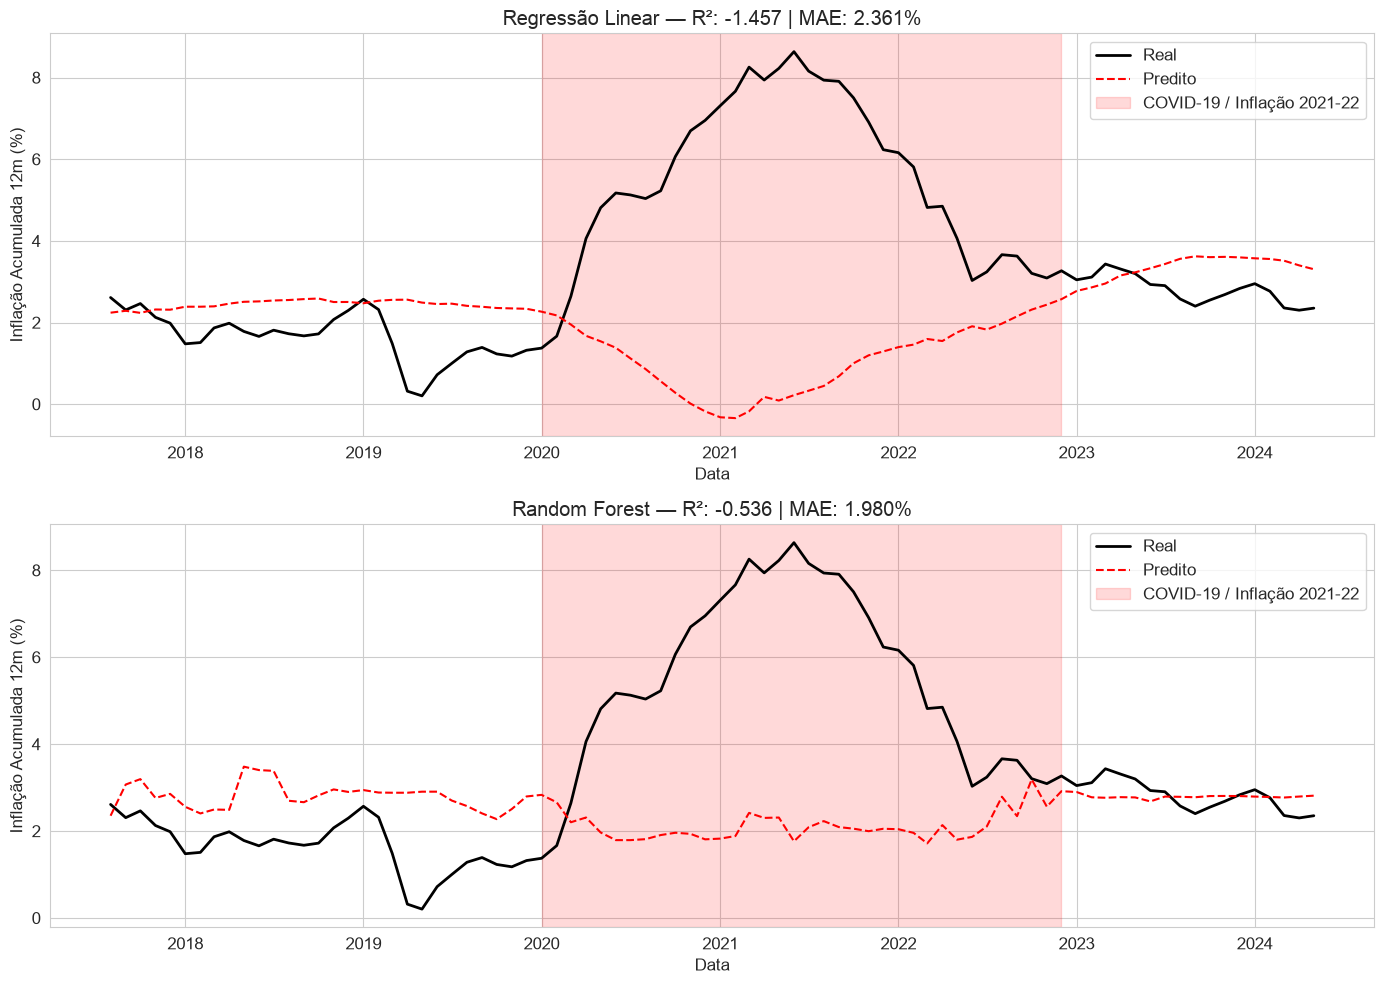

In [770]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

modelos = [
    ('Regressão Linear', y_pred_lr, r2_lr, mae_lr),
    ('Random Forest',    y_pred_rf, r2_rf, mae_rf),
]

for ax, (nome, y_pred, r2, mae) in zip(axes, modelos):
    ax.plot(y_test.index, y_test.values,
            label='Real', color='black', linewidth=2)
    ax.plot(y_test.index, y_pred,
            label='Predito', color='red', linewidth=1.5, linestyle='--')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2022-12-01'),
                alpha=0.15, color='red', label='COVID-19 / Inflação 2021-22')
    ax.set_title(f'{nome} — R²: {r2:.3f} | MAE: {mae:.3f}%')
    ax.set_xlabel('Data')
    ax.set_ylabel('Inflação Acumulada 12m (%)')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [771]:
mask_pre_covid = y_test.index < '2020-01-01'
mask_pos_covid = y_test.index > '2022-12-01'
mask_normal = mask_pre_covid | mask_pos_covid

print("=== Métricas EXCLUINDO período COVID (2020-2022) ===")
for nome, y_pred in [('Regressão Linear', y_pred_lr), ('Random Forest', y_pred_rf)]:
    mae  = mean_absolute_error(y_test[mask_normal], y_pred[mask_normal])
    rmse = np.sqrt(mean_squared_error(y_test[mask_normal], y_pred[mask_normal]))
    r2   = r2_score(y_test[mask_normal], y_pred[mask_normal])
    print(f"\n{nome}:")
    print(f"  MAE:  {mae:.3f}%")
    print(f"  RMSE: {rmse:.3f}%")
    print(f"  R²:   {r2:.3f}")

print("\n=== Métricas APENAS período COVID (2020-2022) ===")
mask_covid = (y_test.index >= '2020-01-01') & (y_test.index <= '2022-12-01')
for nome, y_pred in [('Regressão Linear', y_pred_lr), ('Random Forest', y_pred_rf)]:
    mae  = mean_absolute_error(y_test[mask_covid], y_pred[mask_covid])
    rmse = np.sqrt(mean_squared_error(y_test[mask_covid], y_pred[mask_covid]))
    r2   = r2_score(y_test[mask_covid], y_pred[mask_covid])
    print(f"\n{nome}:")
    print(f"  MAE:  {mae:.3f}%")
    print(f"  RMSE: {rmse:.3f}%")
    print(f"  R²:   {r2:.3f}")

=== Métricas EXCLUINDO período COVID (2020-2022) ===

Regressão Linear:
  MAE:  0.776%
  RMSE: 0.927%
  R²:   -0.491

Random Forest:
  MAE:  0.839%
  RMSE: 1.056%
  R²:   -0.938

=== Métricas APENAS período COVID (2020-2022) ===

Regressão Linear:
  MAE:  4.387%
  RMSE: 5.148%
  R²:   -5.425

Random Forest:
  MAE:  3.439%
  RMSE: 3.979%
  R²:   -2.837


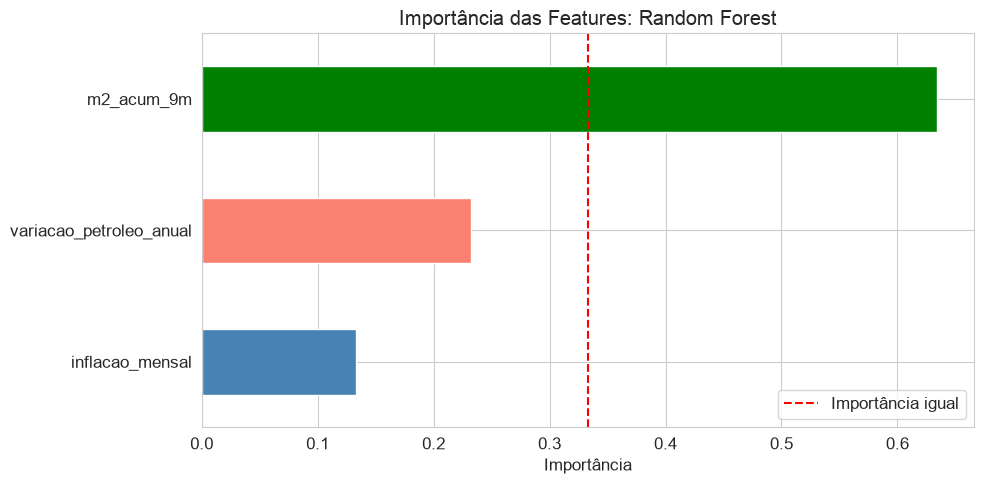


Importância das Features:
  m2_acum_9m                     0.6343 (63.4%)
  variacao_petroleo_anual        0.2325 (23.3%)
  inflacao_mensal                0.1331 (13.3%)


In [772]:
fig, ax = plt.subplots(figsize=(10, 5))

importances = pd.Series(rf.feature_importances_, index=features).sort_values()

importances.plot(kind='barh', ax=ax, color=['steelblue', 'salmon', 'green'])
ax.set_title('Importância das Features: Random Forest')
ax.set_xlabel('Importância')
ax.axvline(1/len(features), color='red', linestyle='--', label='Importância igual')
ax.legend()
plt.tight_layout()
plt.show()

print("\nImportância das Features:")
for feat, imp in sorted(zip(features, rf.feature_importances_), key=lambda x: x[1], reverse=True):
    print(f"  {feat:<30} {imp:.4f} ({imp*100:.1f}%)")

## 7. Avaliação e Reflexão Crítica

### 7.1. Resultados do Modelo

Os dois modelos treinados apresentaram os seguintes resultados no conjunto de teste (2017-2024):

| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| Regressão Linear | 2.361% | 3.481% | -1.457 |
| Random Forest | 1.980% | 2.752% | -0.536 |

O **Random Forest** superou a Regressão Linear em todas as métricas, o que era esperado dado que relações econômicas raramente são lineares.

### 7.2. Interpretação do R² Negativo

O R² negativo pode parecer alarmante à primeira vista, mas precisa ser interpretado no contexto correto.
O R² é calculado como:
$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$
Um R² negativo significa que o modelo performa pior do que simplesmente prever a média. No nosso caso, isso ocorre por dois motivos principais:

**1. O período de teste inclui o COVID-19 (2020-2022):**
Ao separar as métricas por período, o impacto fica evidente:
| Período | MAE (RF) | RMSE (RF) | R² (RF) |
|---|---|---|---|
| Fora do COVID (2017-2019 e 2023-2024) | 0.839% | 1.056% | -0.938 |
| Durante COVID (2020-2022) | 3.439% | 3.979% | -2.837 |

A inflação durante o COVID atingiu **~8.5%**, um valor completamente fora da distribuição histórica vista pelo modelo durante o treino (1990-2017). Nenhum modelo treinado em dados históricos "normais" seria capaz de prever um evento desse tipo — isso é o que a literatura chama de **"black swan"** (evento extremo e imprevisível).

**2. A variância do alvo é baixa em períodos normais:**
Fora do COVID, a inflação acumulada de 12 meses oscila em uma faixa estreita (~1.5% a 3%). Com variância tão baixa, qualquer erro pequeno do modelo resulta em R² negativo, uma limitação da métrica R² para séries temporais estáveis.

### 7.3. Importância das Features

O gráfico de importância das features do Random Forest revelou:

| Feature | Importância |
|---|---|
| `m2_acum_9m` | ~65% |
| `variacao_petroleo_anual` | ~23% |
| `inflacao_mensal` | ~13% |

Isso corrobora com os achados da análise exploratória:
- O **crescimento acumulado do M2** é o principal preditor da inflação futura de 12 meses
- O **petróleo** captura choques de oferta de curto prazo
- A **inflação atual** fornece contexto sobre o momento econômico

### 7.4. Principais Achados da Análise Exploratória

Independentemente das métricas do modelo, a análise exploratória produziu achados economicamente relevantes:

1. **Defasagem do M2:** O crescimento do M2 tem maior correlação com a inflação futura com uma defasagem de 17 a 19 meses.

2. **Nível vs. Variação:** O nível absoluto do M2 e do petróleo têm correlação com o CPI ao longo do tempo. As variações percentuais são muito mais informativas.

3. **M2 acumulado:** A média do crescimento do M2 nos últimos 9 meses é mais preditiva do que a variação pontual, sugerindo que é o crescimento sustentado da oferta monetária que pressiona a inflação, não choques isolados.

4. **COVID-19 como experimento natural:** A expansão massiva do M2 em 2020 (~25%) seguida pela inflação histórica de 2021-2022 (~8.5%) pode ser interpretada como uma confirmação empírica da relação entre oferta monetária e inflação na era moderna.

### 7.5. Limitações do Modelo

1. **Poucos preditores:** O modelo usa apenas 3 features. A inflação é influenciada por dezenas de fatores (taxa de juros, desemprego, câmbio, expectativas, choques geopolíticos, etc.) que não foram
considerados.

2. **Eventos extremos:** O modelo falha completamente em prever eventos fora da distribuição histórica, como pandemias, guerras e crises financeiras.

3. **Não-estacionariedade:** Séries temporais econômicas raramente são estacionárias. Uma abordagem mais rigorosa exigiria testes de estacionariedade e possivelmente diferenciação das séries.

4. **Causalidade vs. Correlação:** As correlações identificadas não implicam necessariamente causalidade. A relação entre M2 e inflação pode ser confundida por outras variáveis (taxa de juros, expectativas, etc.).

5. **Tamanho do dataset:** Com apenas ~400 registros mensais, o dataset é relativamente pequeno para modelos de Machine Learning, limitando a capacidade de generalização.

### 7.6. Sugestões de Melhoria

1. **Adicionar mais features:** Taxa de juros (Federal Funds Rate), taxa de desemprego (UNRATE), índice de expectativas de inflação (T5YIFR).

2. **Modelos de séries temporais:** ARIMA, SARIMA ou Prophet seriam mais adequados para séries temporais do que Random Forest, pois consideram a autocorrelação temporal dos dados.

3. **Modelos de deep learning:** LSTMs (Long Short-Term Memory) são especialmente eficazes para séries temporais longas com dependências de longo prazo.

4. **Tratamento de outliers:** Treinar o modelo excluindo períodos de choques extremos (2008, 2020-2022) e avaliar separadamente pode revelar melhor performance em períodos "normais".

5. **Validação cruzada temporal:** Em vez de uma única divisão treino/teste, usar múltiplas janelas de validação cruzada temporal para uma avaliação mais robusta do modelo.

6. **Índice VIX:** Adicionar o índice de volatilidade do mercado (VIX) como feature poderia ajudar o modelo a identificar períodos de incerteza econômica, melhorando as previsões em períodos de crise.